In [18]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append(os.path.abspath('..'))
from classes import Document
from data_representations import build_ngram_features
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MaxAbsScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score 
from sklearn.dummy import DummyClassifier

In [19]:
# caricamento e lettura del dizionario json contenente i metadati
with open('../dataset/document_info.json', 'r') as f:
    doc_info = json.load(f)

In [20]:
conllu_path = '../profiling_output' # cartella dove sono salvati i file .conllu (aventi annotazioni linguistiche)
all_documents = []
for doc_id, info in doc_info.items(): # iterazione su ogni elemento del dizionario json dove doc_id è la chiave e info contiene il dizionario con 'label' e 'split'
    path = os.path.join(conllu_path, f"{doc_id}.conllu") # costruzione del percorso completo per ogni elemento del dict, unendo la cartella (profiling_output), l'ID del documento e l'estensione .conllu
    doc = Document(path, doc_id, info['split'], info['label']) # istanza della classe Document che permette di estrarre info su 'label' e 'split'
    doc.load_sentences_from_conllu()
    all_documents.append(doc)

# suddivisione dei documenti appena popolati di info linguistiche in base al loro 'split' (set di appartenenza)
train_docs = [d for d in all_documents if d.split == 'training']
val_docs = [d for d in all_documents if d.split == 'validation']
test_docs = [d for d in all_documents if d.split =='test']

# estrazione delle etichette e conversione in array NumPy (necessarie per addestramento e valutazione del modello)
y_train = np.array([d.label for d in train_docs])
y_val = np.array([d.label for d in val_docs])
y_test = np.array([d.label for d in test_docs])

# check delle dimensioni dei subsets 
print(f'Dimensione dataset intero: {len(all_documents)}')
print(f'Dimensione training set: {len(train_docs)}, train labels: {len(y_train)}')
print(f'Dimensione validation set: {len(val_docs)}, validation labels: {len(y_val)}')
print(f'Dimensione test set: {len(test_docs)}, test labels: {len(y_test)}')

Dimensione dataset intero: 4000
Dimensione training set: 2000, train labels: 2000
Dimensione validation set: 1000, validation labels: 1000
Dimensione test set: 1000, test labels: 1000


In [21]:
# dizionario con le configurazioni da testare
configs = [
    {'name': 'morfologica (solo caratteri --> bigrammi, trigrammi, 4-grammi)', 'w': [], 'l': [], 'p': [], 'c': [2, 3, 4]},
    {'name': 'sintattica (solo pos --> bigrammi, trigrammi)', 'w': [], 'l': [], 'p': [2, 3], 'c': []},
    {'name': 'lessicale (solo parole --> unigrammi e bigrammi)', 'w': [1, 2], 'l': [], 'p': [], 'c': []},
    {'name': 'mixata (lemmi, pos e caratteri)', 'w': [], 'l': [1], 'p': [2], 'c': [3]}
]

best_score = 0
best_config = None

for config in configs:
    # richiamo della funzione build_ngram_features passando i documenti (train_docs, val_docs) e il dizionario configs
    # in un solo passaggio la funzione esegue:
    # 1. estrazione > crea n-grammi basandosi sui numeri in config['w'], etc.
    # 2. normalizzazione > trasforma i conteggi in frequenze relative
    # 3. filtraggio > rimuove n-grammi che appaiono meno dell'1% o più del 20% nei documenti
    # 4. trasforma i documenti (rappresentati come dizionari di features) in una matrice numerica sparsa (X_train_cv)
    X_train_cv, _, features_names = build_ngram_features(
        train_docs,
        val_docs, # regola d'oro: mai usare test set per trovare configurazione migliore 
        word_ngrams=config['w'],
        lemma_ngrams = config['l'],
        pos_ngrams = config['p'],
        char_ngrams = config['c'],
        min_perc=0.01, # permette di rimuovere rumore senza perdere troppi dati
        max_perc=0.2 # permette alla SVM di concentrarsi su n-grammi non banali 
    )

    # scaling delle features per riportare i valori nell'intervallo [0,1] mantenendo la matrice sparsa 
    scaler = MaxAbsScaler()
    X_train_scaled = scaler.fit_transform(X_train_cv) # il metodo fit consente allo scaler di apprendere il valore massimo assoluto (parametro) per ogni colonna della matrice 

    model = LinearSVC(dual=False, random_state = 26, max_iter=5000) # definizione della SVM lineare 
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='f1_macro') # esecuzione della k-fold cv solo su training set e restituisce un array con i 5 punteggi di F1 (macro) ottenuti
    avg_score = np.mean(scores) # misura la capacità di generalizzazione per ogni config 

    print(f"Configurazione testata: {config['name']} con una F1 (macro) di {avg_score:.4f}\n")
    
    if avg_score > best_score:
        best_score = avg_score
        best_config = config

print(f"La miglior configurazione selezionata è: {best_config['name']} con una F1 (macro) di {best_score:.4f}") 

Rimosse feature che compaiono in meno di 20 documenti e in più di 400 documenti.
Si passa da 126769 a 17192 features.
Configurazione testata: morfologica (solo caratteri --> bigrammi, trigrammi, 4-grammi) con una F1 (macro) di 0.9680

Rimosse feature che compaiono in meno di 20 documenti e in più di 400 documenti.
Si passa da 2934 a 1093 features.
Configurazione testata: sintattica (solo pos --> bigrammi, trigrammi) con una F1 (macro) di 0.8928

Rimosse feature che compaiono in meno di 20 documenti e in più di 400 documenti.
Si passa da 408898 a 7387 features.
Configurazione testata: lessicale (solo parole --> unigrammi e bigrammi) con una F1 (macro) di 0.9730

Rimosse feature che compaiono in meno di 20 documenti e in più di 400 documenti.
Si passa da 71390 a 6511 features.
Configurazione testata: mixata (lemmi, pos e caratteri) con una F1 (macro) di 0.9585

La miglior configurazione selezionata è: lessicale (solo parole --> unigrammi e bigrammi) con una F1 (macro) di 0.9730


Rimosse feature che compaiono in meno di 20 documenti e in più di 400 documenti.
Si passa da 408898 a 7387 features.

==================== ANALISI FOLD-BY-FOLD: VALIDATION SET ====================
F1 score fold 1: 0.95, baseline: 0.32
F1 score fold 2: 0.94, baseline: 0.33
F1 score fold 3: 0.97, baseline: 0.33
F1 score fold 4: 0.95, baseline: 0.30
F1 score fold 5: 0.94, baseline: 0.29

Overall f1: 0.95

VALUTAZIONE FINALE: VALIDATION SET
Baseline F1 (macro) (VALIDATION SET): 0.3333

REPORT BASELINE (DUMMY):
              precision    recall  f1-score   support

       Human       0.50      1.00      0.67       500
          AI       0.00      0.00      0.00       500

    accuracy                           0.50      1000
   macro avg       0.25      0.50      0.33      1000
weighted avg       0.25      0.50      0.33      1000


REPORT MODELLO SVM:
              precision    recall  f1-score   support

       Human       0.96      0.99      0.98       500
          AI       0.99      0.

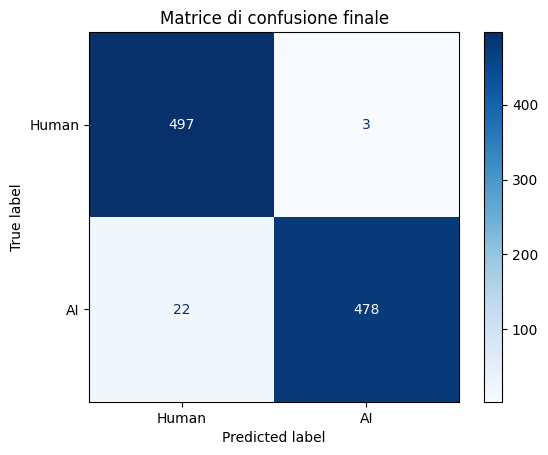

Rimosse feature che compaiono in meno di 20 documenti e in più di 400 documenti.
Si passa da 408898 a 7387 features.

==================== ANALISI FOLD-BY-FOLD: TEST SET ====================
F1 score fold 1: 0.76, baseline: 0.32
F1 score fold 2: 0.83, baseline: 0.33
F1 score fold 3: 0.85, baseline: 0.33
F1 score fold 4: 0.84, baseline: 0.30
F1 score fold 5: 0.77, baseline: 0.29

Overall f1: 0.81

VALUTAZIONE FINALE: TEST SET
Baseline F1 (macro) (TEST SET): 0.3333

REPORT BASELINE (DUMMY):
              precision    recall  f1-score   support

       Human       0.50      1.00      0.67       500
          AI       0.00      0.00      0.00       500

    accuracy                           0.50      1000
   macro avg       0.25      0.50      0.33      1000
weighted avg       0.25      0.50      0.33      1000


REPORT MODELLO SVM:
              precision    recall  f1-score   support

       Human       0.72      0.98      0.83       500
          AI       0.97      0.62      0.76      

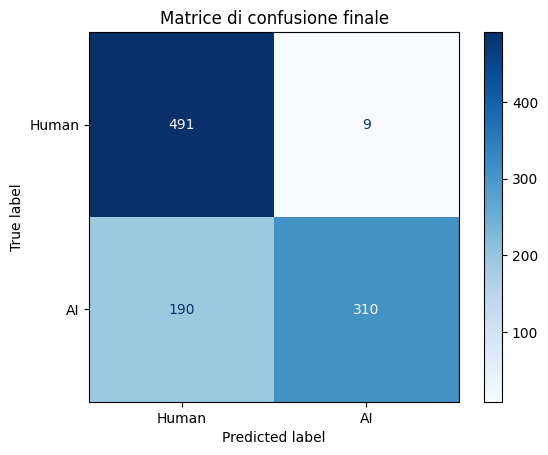

In [22]:
# creazione di un dict che raccoglie i sets su cui si vuole testare il modello finale individuato nella fase di cross validation
evaluation_targets = [
    (val_docs, y_val, "VALIDATION SET"),
    (test_docs, y_test, "TEST SET")
]

# inizializzazione di un ciclo per processare i due set di valutazione separatamente 
for docs, labels, name in evaluation_targets:
    X_train_final, X_eval_final, features_names = build_ngram_features(
        train_docs, # per il training del modello finale 
        docs, # è val_docs al primo giro e test_docs al secondo 
        word_ngrams = best_config['w'],
        lemma_ngrams=best_config['l'],
        pos_ngrams=best_config['p'],
        char_ngrams = best_config['c'],
        min_perc = 0.01,
        max_perc = 0.2
    )
    
    scaler = MaxAbsScaler()
    X_train_final_scaled = scaler.fit_transform(X_train_final)
    X_eval_final_scaled = scaler.transform(X_eval_final) # non viene applicato il metodo fit perché è il set su cui il modello deve fare predizioni
    
    baseline = DummyClassifier(strategy="most_frequent") # modello che sceglie la classe più frequente per fare le sue predizioni
    baseline.fit(X_train_final_scaled, y_train) # fit per apprendimento della classe più frequente (y), ovvero la moda del dataset
    baseline_preds = baseline.predict(X_eval_final_scaled)
    baseline_score = f1_score(labels, baseline_preds, average='macro') 
    
    # addestramento del modello finale con la configurazione vincitrice 
    final_model = LinearSVC(dual = False, random_state=26, max_iter=5000)
    final_model.fit(X_train_final_scaled, y_train)
    y_pred = final_model.predict(X_eval_final_scaled)
    
    print(f"\n{'='*20} ANALISI FOLD-BY-FOLD: {name} {'='*20}")
    # split del dataset in 5 folds 
    splitter = KFold(n_splits=5, random_state=26, shuffle=True)
    
    # inizializzazione delle liste per accumulare le etichette reali e le predizioni utili per il calcolo dell'F1 complessivo
    all_y_true = []
    all_y_pred = []

    for i, (train_ids, test_ids) in enumerate(splitter.split(X_eval_final_scaled)): #splitter.split fornisce gli indici per dividere i dati (4 folds per il training e 1 per il test)
        fold_X_train = X_eval_final_scaled[train_ids]
        fold_y_train = labels[train_ids]
        fold_X_test = X_eval_final_scaled[test_ids]
        fold_y_test = labels[test_ids]

        final_model.fit(fold_X_train, fold_y_train)
        fold_y_pred = final_model.predict(fold_X_test)

        # calcolo di F1 score per il fold corrente 
        fold_f1 = f1_score(fold_y_test, fold_y_pred, average='macro') 
    
        baseline_fold = DummyClassifier(strategy="most_frequent")
        baseline_fold.fit(fold_X_train, fold_y_train)
        baseline_fold_f1 = f1_score(fold_y_test, baseline_fold.predict(fold_X_test), average='macro') 

        # i risultati ottenuti vengono aggiungi alle liste inizializzate in precedenza
        all_y_true += fold_y_test.tolist() 
        all_y_pred += fold_y_pred.tolist()
        
        print(f"F1 score fold {i+1}: {fold_f1:.2f}, baseline: {baseline_fold_f1:.2f}") # 

    overall_f1 = f1_score(all_y_true, all_y_pred, average='macro') 
    print(f"\nOverall f1: {overall_f1:.2f}") 

    # valutazione delle prestazioni del modello vincitore sul set corrente 
    cv_scores = cross_val_score(final_model, X_eval_final_scaled, labels, cv=5, scoring='f1_macro')
    
    # la decision function calcola la distanza di ogni documento dal confine di decisione
    scores = final_model.decision_function(X_eval_final_scaled)

    # se il ciclo fro sta processando il test set (vedi evaluation_targets) i risultati vengono salvati per l'analisi linguistica 
    if name == "TEST SET":
        qualitative_results = {'docs': docs, 'labels': labels, 'preds': y_pred, 'scores': scores} 

    print(f"\n" + "="*50)
    print(f"VALUTAZIONE FINALE: {name}")
    print(f"="*50)
    print(f"Baseline F1 (macro) ({name}): {baseline_score:.4f}")
    
    print(f"\nREPORT BASELINE (DUMMY):")
    print(classification_report(labels, baseline_preds, target_names=['Human', 'AI'], zero_division=0))
    
    print(f"\nREPORT MODELLO SVM:")
    print(classification_report(labels, y_pred, target_names=['Human', 'AI']))
    
    print(f"Score della decision function (primi 5): {np.round(scores[:5], 3)}")

    cm = confusion_matrix(labels, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Human', 'AI'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Matrice di confusione finale")
    plt.show()